# Entropy-Regularized SPMD

## Problems

Both problems are the team's baseline environments (`baseline.py`, `baseline_blackjack.py`), imported
here, not copied, so this notebook always uses the same rules as the baseline. Both are written with
**costs** (lower is better) and discount factor γ = 0.9.

Each environment provides `n_states`, `n_actions`, `gamma` and a vectorized `step(states, actions, rng)`
that returns `(next_states, costs, done)`, which is everything SPMD needs to sample Q.

In [ ]:
import sys
from pathlib import Path

import numpy as np

# The team's code lives in the repository root, one level above this folder.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "baseline.py").exists())
sys.path.insert(0, str(REPO))

from baseline import GridWorld
from baseline_blackjack import Blackjack

from entropy_reg_spmd import run_pmd

rng = np.random.default_rng(0)

### GridWorld

10 × 10 board, start in the top-left square (S = 0). Actions: up, down, left, right. The intended move
happens with probability 0.8; otherwise one of the other three directions is taken. Walls clip
movement. Each move costs 0.2 from an ordinary square, 1.0 from a hazard (H) and 0 from a goal (G).
From a goal or hazard the agent is sent back to the start with probability 0.8. Runs never
terminate, so the agent should reach a goal while avoiding hazards.

In [ ]:
gridworld = GridWorld()
print(f"states: {gridworld.n_states}, actions: {gridworld.n_actions} {gridworld.action_names}, gamma: {gridworld.gamma}")

board = np.full((gridworld.rows, gridworld.cols), ".")
board.flat[list(gridworld.goals)] = "G"
board.flat[list(gridworld.hazards)] = "H"
board.flat[gridworld.start] = "S"
print("\n".join(" ".join(row) for row in board))

# One sampled step from the start for each action: (next state, cost, done).
states = gridworld.initial_states(4, rng)
next_states, costs, done = gridworld.step(states, np.arange(4), rng)
print("\nfrom the start:", [(name, int(s), float(c)) for name, s, c in zip(gridworld.action_names, next_states, costs)])

states: 100, actions: 4 ('up', 'down', 'left', 'right'), gamma: 0.9
S . . . . . . . . G
. . H . . . . H . .
. . . . H . . . . .
. . . . . . H . . .
. . . H . . . . . .
. . . . . . . . H .
. . H . . . . . . .
. . . . . H . . . .
. H . . . . . H . .
G . . . . . . . . G

from the start: [('up', 0, 0.2), ('down', 10, 0.2), ('left', 0, 0.2), ('right', 0, 0.2)]


### Blackjack

Simplified game from the project handout: cards 2–5 with equal probability, no aces. A state is
(player total 4–11, dealer's visible card 2–5), so 32 states. Actions: stop (0) or draw (1). Going
above 11 is a bust. When the player stops, the dealer draws until reaching 9 or more. Terminal cost:
win −1, draw 0, loss +1. Every episode starts from the fixed hand (total 8, dealer shows 3).

In [ ]:
blackjack = Blackjack()
start = int(blackjack.encode(blackjack.evaluation_total, blackjack.evaluation_dealer))
print(f"states: {blackjack.n_states}, actions: {blackjack.n_actions} {blackjack.action_names}, gamma: {blackjack.gamma}")
print(f"start state: {start} = (total {blackjack.evaluation_total}, dealer {blackjack.evaluation_dealer})")

# Ten sampled "stop" moves from the start: the dealer plays out, cost -1 win / 0 draw / +1 loss.
states = blackjack.initial_states(10, rng)
_, costs, done = blackjack.step(states, np.zeros(10, dtype=int), rng)
print("stop from the start, 10 samples:", costs.astype(int).tolist(), "done:", bool(done.all()))

states: 32, actions: 2 ('stop', 'draw'), gamma: 0.9
start state: 17 = (total 8, dealer 3)
stop from the start, 10 samples: [1, 1, 1, 1, 1, -1, 1, 1, 1, 1] done: True


## Online validation: baseline SPMD vs Entropy-Regularized SPMD

Following the project guideline, every method learns from **online sampling** only: each iteration
plays whole episodes from the start state, following the current policy, and estimates Q from the
returns it observed (`estimators.online_q`). Pairs the policy never visited get no new information:
an untried action gets its state's average return, and an unvisited state gets a constant row.

- **Baseline SPMD:** the team's Euclidean update, `utils.mirror_step`.
- **Entropy-Regularized SPMD:** `run_pmd` above, with τ = 0 (plain KL) and τ > 0. With τ > 0, each
  step's cost includes τ Σ_a π(a|s) log π(a|s), so the sampled Q is the regularized Q.
- **Budget:** each run stops when its environment steps run out: 2.4M for GridWorld and 120k for
  blackjack.
- **Protocol:**
  - Each method's step size is tuned on seeds 100–102 and tested on fresh seeds 200–204.
  - After every iteration the policy is scored **exactly** from the model, with no sampling noise.
  - The score is the gap to the optimal cost from the start state (0 = optimal).

In [ ]:
sys.path.insert(0, str(REPO / "Entropy-Regularized SPMD"))
import utils
from estimators import online_q
from exact_eval import ExactScorer

TAUS = [0.0, 0.001, 0.01, 0.03, 0.1]
BASELINE_STEP_SIZES = [0.1, 0.5, 1.0]
PMD_STEP_SIZES = [1.0, 5.0, 20.0]
TUNING_SEEDS = [100, 101, 102]
TEST_SEEDS = [200, 201, 202, 203, 204]
GRID = np.linspace(0, 1, 101)  # fractions of the budget at which learning curves are recorded

# name: (environment, episodes per iteration, episode horizon, budget in environment steps)
PROBLEMS = {
    "GridWorld": (gridworld, 100, 80, 2_400_000),
    "Blackjack": (blackjack, 200, 8, 120_000),
}


class EntropyCost:
    """The same environment, with tau * sum_a pi log pi added to every step's cost."""

    def __init__(self, env, policy, tau):
        self.env, self.gamma = env, env.gamma
        self.n_states, self.n_actions = env.n_states, env.n_actions
        self.extra = tau * np.sum(policy * np.log(np.maximum(policy, 1e-300)), axis=1)

    def initial_states(self, count, rng):
        return self.env.initial_states(count, rng)

    def step(self, states, actions, rng):
        next_states, costs, done = self.env.step(states, actions, rng)
        return next_states, costs + self.extra[states], done


def methods():
    """(name, tau, step sizes to tune over, update). Updates take cost-valued Q."""
    yield "baseline SPMD", 0.0, BASELINE_STEP_SIZES, utils.mirror_step
    for tau in TAUS:
        yield f"PMD, tau={tau:g}", tau, PMD_STEP_SIZES, (lambda p, q, eta, tau=tau: run_pmd(p, q, eta, tau))


def train_online(env, episodes, horizon, budget, update, eta, tau, seed, scorer):
    """Online SPMD from the uniform policy; returns the exact gap at each fraction in GRID."""
    rng = np.random.default_rng(seed)
    policy = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    used, fractions, gaps = 0, [0.0], [scorer.score(policy) - scorer.optimal]
    while used < budget:
        sampled = EntropyCost(env, policy, tau) if tau > 0 else env
        q, steps = online_q(sampled, policy, episodes, horizon, rng)
        used += steps
        policy = update(policy, q, eta)
        fractions.append(used / budget)
        gaps.append(scorer.score(policy) - scorer.optimal)
    # The gap at fraction f is that of the first policy whose samples reach f.
    return np.array(gaps)[np.searchsorted(fractions, GRID, side="left")]

In [ ]:
# Tune step sizes, then test on fresh seeds (about 2 minutes).
curves, chosen = {}, {}
for problem, (env, episodes, horizon, budget) in PROBLEMS.items():
    scorer = ExactScorer(env)
    print(f"{problem}: optimal cost {scorer.optimal:.4f}, budget {budget:,} steps")
    for name, tau, step_sizes, update in methods():
        tuning = {eta: np.mean([train_online(env, episodes, horizon, budget, update, eta, tau, seed, scorer)[-1]
                                for seed in TUNING_SEEDS]) for eta in step_sizes}
        eta = min(tuning, key=tuning.get)
        chosen[problem, name] = eta
        curves[problem, name] = np.array([train_online(env, episodes, horizon, budget, update, eta, tau, seed, scorer)
                                          for seed in TEST_SEEDS])
        print(f"  {name:14s} step size {eta:<4g} final gap {curves[problem, name][:, -1].mean():.4f}")

GridWorld: optimal cost 1.9533, budget 2,400,000 steps
  baseline SPMD  step size 0.5  final gap 0.0141
  PMD, tau=0     step size 5    final gap 0.0225
  PMD, tau=0.001 step size 5    final gap 0.0061
  PMD, tau=0.01  step size 1    final gap 0.0518
  PMD, tau=0.03  step size 1    final gap 0.0768
  PMD, tau=0.1   step size 1    final gap 0.1089
Blackjack: optimal cost 0.2750, budget 120,000 steps
  baseline SPMD  step size 0.5  final gap 0.0000
  PMD, tau=0     step size 5    final gap 0.0000
  PMD, tau=0.001 step size 1    final gap 0.0001
  PMD, tau=0.01  step size 1    final gap 0.0009
  PMD, tau=0.03  step size 1    final gap 0.0044
  PMD, tau=0.1   step size 20   final gap 0.0859


### Results

Final gap over the 5 test seeds (mean ± standard error). The last columns compare each method with
baseline SPMD: z ≤ −2 counts as better, and z ≥ +2 with a difference of at least 0.001 counts as worse.

In [ ]:
print(f"{'problem':10s} {'method':15s} {'step':>5s} {'gap@25%':>8s} {'gap@50%':>8s} {'final gap':>16s} {'vs baseline':>12s} {'z':>6s}  verdict")
for problem in PROBLEMS:
    base = curves[problem, "baseline SPMD"][:, -1]
    for name, tau, _, _ in methods():
        runs = curves[problem, name]
        final = runs[:, -1]
        diff = final.mean() - base.mean()
        se_diff = np.sqrt(final.var(ddof=1) / len(final) + base.var(ddof=1) / len(base))
        z = diff / se_diff if se_diff > 0 else 0.0
        verdict = "" if name == "baseline SPMD" else (
            "better" if z <= -2 else "worse" if z >= 2 and diff >= 0.001 else "tie")
        final_text = f"{final.mean():.4f} ± {final.std(ddof=1) / np.sqrt(len(final)):.4f}"
        print(f"{problem:10s} {name:15s} {chosen[problem, name]:5g} {runs[:, 25].mean():8.4f} {runs[:, 50].mean():8.4f} "
              f"{final_text:>16s} {diff:+12.4f} {z:+6.1f}  {verdict}")
    print()

problem    method           step  gap@25%  gap@50%        final gap  vs baseline      z  verdict
GridWorld  baseline SPMD     0.5   0.0477   0.0330  0.0141 ± 0.0031      +0.0000   +0.0  
GridWorld  PMD, tau=0          5   0.0390   0.0273  0.0225 ± 0.0121      +0.0083   +0.7  tie
GridWorld  PMD, tau=0.001      5   0.0379   0.0259  0.0061 ± 0.0017      -0.0081   -2.3  better
GridWorld  PMD, tau=0.01       1   0.0663   0.0594  0.0518 ± 0.0006      +0.0376  +11.9  worse
GridWorld  PMD, tau=0.03       1   0.0797   0.0769  0.0768 ± 0.0006      +0.0626  +19.9  worse
GridWorld  PMD, tau=0.1        1   0.1095   0.1086  0.1089 ± 0.0005      +0.0948  +30.2  worse

Blackjack  baseline SPMD     0.5   0.0000   0.0000  0.0000 ± 0.0000      +0.0000   +0.0  
Blackjack  PMD, tau=0          5   0.0000   0.0000  0.0000 ± 0.0000      +0.0000   +1.6  tie
Blackjack  PMD, tau=0.001      1   0.0004   0.0001  0.0001 ± 0.0000      +0.0001   +6.7  tie
Blackjack  PMD, tau=0.01       1   0.0010   0.0015  0.0009 ± 0

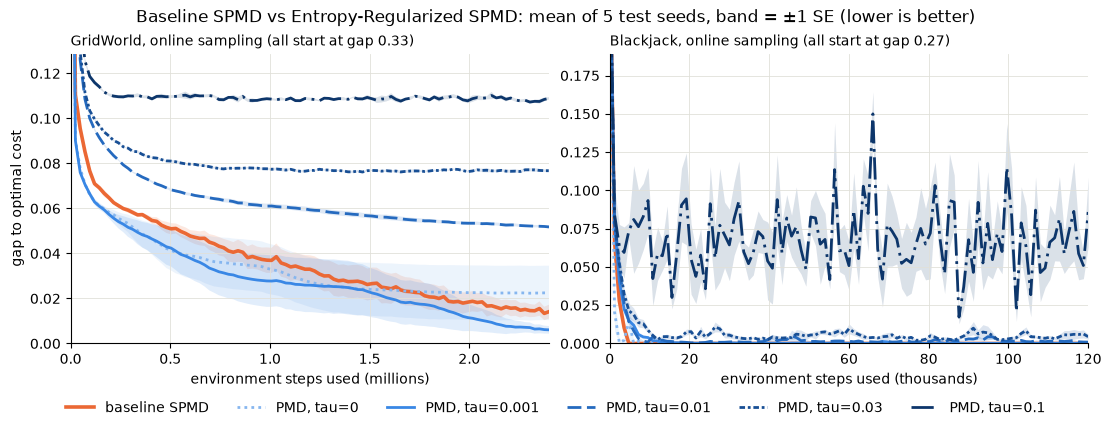

In [ ]:
import matplotlib.pyplot as plt

colors = {"baseline SPMD": "#eb6834", "PMD, tau=0": "#86b6ef", "PMD, tau=0.001": "#3987e5",
          "PMD, tau=0.01": "#256abf", "PMD, tau=0.03": "#184f95", "PMD, tau=0.1": "#0d366b"}
styles = {"PMD, tau=0": (0, (1, 1.5)), "PMD, tau=0.01": (0, (5, 2)), "PMD, tau=0.03": (0, (2, 1, 1, 1)),
          "PMD, tau=0.1": (0, (8, 2, 1, 2))}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, (problem, (env, episodes, horizon, budget)) in zip(axes, PROBLEMS.items()):
    scale, unit = (1e6, "millions") if budget >= 1e6 else (1e3, "thousands")
    x = GRID * budget / scale
    late = 0
    for name, *_ in methods():
        runs = curves[problem, name]
        mean, se = runs.mean(0), runs.std(0, ddof=1) / np.sqrt(len(runs))
        ax.fill_between(x, mean - se, mean + se, color=colors[name], alpha=0.15, linewidth=0)
        ax.plot(x, mean, color=colors[name], linestyle=styles.get(name, "-"),
                linewidth=2.6 if name == "baseline SPMD" else 2, label=name)
        late = max(late, (mean + se)[GRID >= 0.1].max())
    start = curves[problem, "baseline SPMD"][:, 0].mean()
    ax.set_ylim(0, min(start, 1.15 * late))  # all methods start from the uniform policy's gap
    ax.set_xlim(0, x[-1])
    ax.set_title(f"{problem}, online sampling (all start at gap {start:.2f})", loc="left", fontsize=10)
    ax.set_xlabel(f"environment steps used ({unit})")
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("gap to optimal cost")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=6, frameon=False)
fig.suptitle("Baseline SPMD vs Entropy-Regularized SPMD: mean of 5 test seeds, band = ±1 SE (lower is better)")
plt.show()